# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [141]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Write your code here

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(plt.matplotlib.__version__)
print(sns.__version__)

# complete

# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.4.6
Pandas version: 2.2.3
3.10.0
0.13.2


In [142]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [143]:
# Write your code here
S = np.array([[10,4],[2,1],[7,3],[1,2]])
theta = np.array([0.3,0.7])
bias = 0.5

# 1. Compute linear combination z
z = np.dot(S,theta)+bias

# 2. Compute sigmoid probabilities and predict spam (probability >= 0.5)
probabilities = 1/(1+np.exp(-z))

# Identify predicted spam emails
predicted_spam = probabilities >= 0.5

In [144]:
# Auto-graded cell (S)
# Skip it

In [145]:
# Auto-graded cell (theta)
# Skip it

In [146]:
# Auto-graded cell (bias)
# Skip it

In [147]:
# Auto-graded cell (z)
# Skip it

In [148]:
# Auto-graded cell (probabilities)
# Skip it

In [149]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [150]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [151]:
# Auto graded cell (log)
# skip it

In [152]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"

# Write your code here
random_indexes = rng.choice(log.index, size=12, replace=False)
log.loc[random_indexes, "failed_attempts"] =rng.integers(5, 11, size=12)


In [153]:
# Autograded cell (Failed attempts)
# Skip it

In [154]:
# Insert 10 missing values randomly

# Write your code here
for _ in range(10):
  row_idx = rng.choice(log.index)
  col_name = rng.choice(log.columns)
  log.loc[row_idx, col_name]


In [155]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [156]:
# Write your code here
ru_log_at_least_five_attempts = len(log[(log["country"] == "RU") & (log["failed_attempts"] >= 5)])

In [157]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [158]:
# Write your code here

user_max_failed_attempts = (
    log.groupby("user")["failed_attempts"]
    .sum()
    .sort_values(ascending=False)
)

In [159]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [160]:
# Write your code here
log['long_session'] = (log["duration_min"] > 30).astype(int)

In [161]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

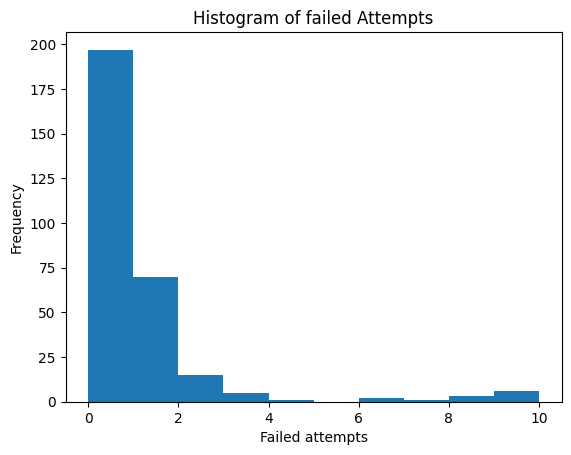

In [162]:
# Draw the histogram of failed_attempts.
# Write your code here
import matplotlib.pyplot as plt

plt.hist(log['failed_attempts'])
plt.xlabel('Failed attempts')
plt.ylabel('Frequency')
plt.title('Histogram of failed Attempts')
plt.show()

In [163]:
# Auto-graded cell - Skip it...

In [164]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

IndentationError: unexpected indent (1357432129.py, line 2)

In [167]:
# Write your code here
answer_q2 = "B"

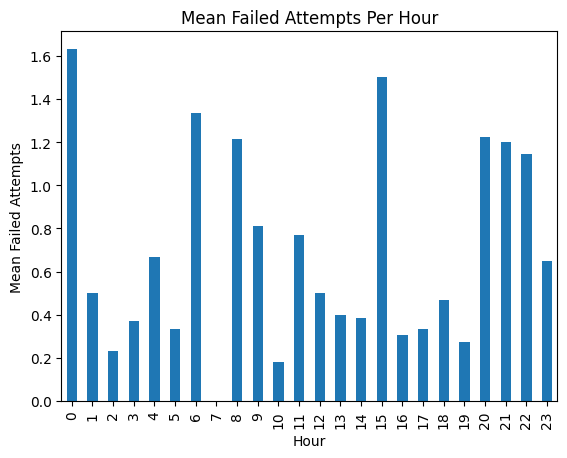

In [169]:
# 3. Draw a bar chart of the mean failed_attempts per night value.

# Write your code here
import matplotlib.pyplot as plt

mean_per_night = log.groupby('hour')['failed_attempts'].mean()

plt.figure()
mean_per_night.plot(kind='bar')
plt.xlabel('Hour')
plt.ylabel('Mean Failed Attempts')
plt.title('Mean Failed Attempts Per Hour')
plt.show()




In [170]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [171]:
# Write your code here
# Please write a sentence response instead of code
answer_g1 ="X[:,2] returns all  rows from the third column of X "

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [177]:
# Write your code here
log.isnull().sum()

,0
user,0
hour,0
failed_attempts,0
country,0
duration_min,0
long_session,0


Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

In [179]:
# Write your code here
answer_q3 = "Boxplot"

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [180]:
# Write your code here
answer_q4 ="To ensure all features contribute equally to the mpdel and prevent large-scale values from dominating."

Commit the logins_clean.csv.(0.5 point)

In [182]:
# save the cleaned table in login_clean.csv
# Write your code here
log.to_csv("logins_clean.csv", index=False)

In [178]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [187]:
# Write your code here


In [183]:
import numpy as np
import pandas as pd
